# Book Editions, Popularity and Reader Ratings

## Introduction

This project explores the relationship between the number of
catalogued editions, reader popularity and average book ratings.

It combines Goodreads data distributed through Kaggle with
catalogue information from Open Library.

Popularity is represented by the number of Goodreads ratings.
The number of editions is measured using Open Library catalogue data.

The analysis investigates associations. It does not establish
that more editions cause greater popularity or higher ratings.

## Research Questions

1. Is the number of catalogued editions associated with the
   number of Goodreads ratings?

2. Is the number of Goodreads ratings associated with the
   average reader rating?

3. How sensitive are the findings to low rating counts,
   the choice of a representative edition and extreme observations?

A possible additional analysis will compare mean reader ratings
between groups defined by edition count. The grouping rule and
test assumptions will be documented before performing the test.

## Data Sources

### Goodreads data distributed through Kaggle

Source:
https://www.kaggle.com/datasets/jealousleopard/goodreadsbooks

Main variables:
- `isbn13`: identifier used to match editions;
- `title`: book title;
- `authors`: author and contributor information;
- `average_rating`: average rating reported in the dataset;
- `ratings_count`: number of ratings reported in the dataset.

### Open Library

Source:
https://openlibrary.org/

API documentation:
https://openlibrary.org/dev/docs/api/search

Main variables:
- `isbn13`: identifier used for matching;
- `openlibrary_work_id`: identifier of the literary work;
- `edition_count`: number of editions catalogued for that work;
- `retrieved_on`: date of data retrieval.

The saved Open Library pilot responses were retrieved on
20 November 2026. The Goodreads snapshot date has not yet
been established.

The two sources describe different systems and may represent
different points in time.

## Unit of Analysis and Pilot Scope

The final analysis will use one row per literary work.

An ISBN identifies an edition, while an Open Library work ID
groups editions of a work. Matching will therefore start with
ISBNs, followed by work-level validation and deduplication.

When several Goodreads records map to the same work, a documented
rule will select a representative record. Rating counts from
different editions will not be summed without evidence that
they are non-overlapping.

The initial pilot contains five deliberately selected books.
Its purpose is to validate loading, matching and saving data.

The pilot is not a representative sample and will not be used
for statistical conclusions.

A larger dataset will be prepared before the main analysis.

## Pilot Data Integration

This section checks the data integration workflow using five books.

The steps are:
1. Load the Goodreads and Open Library tables.
2. Check identifiers and data types.
3. Merge the tables by ISBN-13.
4. Inspect matching results and missing values.
5. Save the merged pilot dataset.

These steps validate data handling. The five deliberately selected
books will not be used for statistical conclusions.

In [1]:
from pathlib import Path

import pandas as pd

RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
kaggle = pd.read_csv(
    RAW_DIR / "kaggle_pilot.csv",
    dtype={
        "isbn": "string",
        "isbn13": "string",
    },
)

openlibrary = pd.read_csv(
    RAW_DIR / "openlibrary_pilot.csv",
    dtype={
        "isbn13": "string",
        "openlibrary_work_id": "string",
    },
)

In [3]:
kaggle[
    [
        "title",
        "authors",
        "isbn13",
        "average_rating",
        "ratings_count",
    ]
]

,title,authors,isbn13,average_rating,ratings_count
0,Pride and Prejudice,Jane Austen,9780192802385,4.26,2399
1,Great Expectations,Charles Dickens/David Trotter/Charlotte Mitchell,9780141439563,3.77,14228
2,Wuthering Heights,Emily Brontë,9780140620122,3.85,2155
3,Jane Eyre,Charlotte Brontë/Michael Mason,9780142437209,4.12,1409369
4,Dracula,Bram Stoker,9780140620634,3.99,1683


In [4]:
openlibrary[
    [
        "openlibrary_title",
        "openlibrary_authors",
        "isbn13",
        "openlibrary_work_id",
        "edition_count",
    ]
]

,openlibrary_title,openlibrary_authors,isbn13,openlibrary_work_id,edition_count
0,Pride and Prejudice,Jane Austen,9780192802385,OL66554W,4042
1,Great Expectations,Charles Dickens,9780141439563,OL8721462W,1489
2,Wuthering Heights,Emily Brontë,9780140620122,OL21177W,2889
3,Jane Eyre,Charlotte Brontë,9780142437209,OL1095427W,1170
4,Dracula,Bram Stoker,9780140620634,OL85892W,1920


In [5]:
kaggle.info()
openlibrary.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   bookID              5 non-null      int64  
 1   title               5 non-null      str    
 2   authors             5 non-null      str    
 3   average_rating      5 non-null      float64
 4   isbn                5 non-null      string 
 5   isbn13              5 non-null      string 
 6   language_code       5 non-null      str    
 7   num_pages           5 non-null      int64  
 8   ratings_count       5 non-null      int64  
 9   text_reviews_count  5 non-null      int64  
 10  publication_date    5 non-null      str    
 11  publisher           5 non-null      str    
dtypes: float64(1), int64(4), str(5), string(2)
memory usage: 1.0 KB
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------  

In [6]:
key_checks = pd.DataFrame(
    {
        "source": ["Kaggle / Goodreads", "Open Library"],
        "rows": [
            len(kaggle),
            len(openlibrary),
        ],
        "missing_isbn13": [
            kaggle["isbn13"].isna().sum(),
            openlibrary["isbn13"].isna().sum(),
        ],
        "duplicate_isbn13": [
            kaggle["isbn13"].duplicated().sum(),
            openlibrary["isbn13"].duplicated().sum(),
        ],
    }
)

key_checks

,source,rows,missing_isbn13,duplicate_isbn13
0,Kaggle / Goodreads,5,0,0
1,Open Library,5,0,0


### Matching Strategy

The tables are matched by ISBN-13.

A left join preserves every Goodreads record and makes unmatched
records visible.

The pilot expects one record per ISBN in each input table,
so the merge uses one-to-one validation.

Titles and author information will also be inspected to check
whether the matched records refer to the same literary work.

In [7]:
assert kaggle["isbn13"].notna().all(), "Missing ISBN in Kaggle data"
assert openlibrary["isbn13"].notna().all(), "Missing ISBN in Open Library data"

books_pilot = kaggle.merge(
    openlibrary,
    on="isbn13",
    how="left",
    validate="one_to_one",
    indicator=True,
)

books_pilot[
    [
        "title",
        "isbn13",
        "average_rating",
        "ratings_count",
        "edition_count",
        "openlibrary_work_id",
        "_merge",
    ]
]

,title,isbn13,average_rating,ratings_count,edition_count,openlibrary_work_id,_merge
0,Pride and Prejudice,9780192802385,4.26,2399,4042,OL66554W,both
1,Great Expectations,9780141439563,3.77,14228,1489,OL8721462W,both
2,Wuthering Heights,9780140620122,3.85,2155,2889,OL21177W,both
3,Jane Eyre,9780142437209,4.12,1409369,1170,OL1095427W,both
4,Dracula,9780140620634,3.99,1683,1920,OL85892W,both


In [8]:
merge_summary = pd.DataFrame(
    {
        "check": [
            "Goodreads rows before merge",
            "Rows after merge",
            "Matched rows",
            "Unmatched Goodreads rows",
            "Unique matched works",
        ],
        "value": [
            len(kaggle),
            len(books_pilot),
            books_pilot["_merge"].eq("both").sum(),
            books_pilot["_merge"].eq("left_only").sum(),
            books_pilot["openlibrary_work_id"].nunique(),
        ],
    }
)

merge_summary

,check,value
0,Goodreads rows before merge,5
1,Rows after merge,5
2,Matched rows,5
3,Unmatched Goodreads rows,0
4,Unique matched works,5


In [9]:
books_pilot[
    [
        "title",
        "openlibrary_title",
        "authors",
        "openlibrary_authors",
    ]
]

,title,openlibrary_title,authors,openlibrary_authors
0,Pride and Prejudice,Pride and Prejudice,Jane Austen,Jane Austen
1,Great Expectations,Great Expectations,Charles Dickens/David Trotter/Charlotte Mitchell,Charles Dickens
2,Wuthering Heights,Wuthering Heights,Emily Brontë,Emily Brontë
3,Jane Eyre,Jane Eyre,Charlotte Brontë/Michael Mason,Charlotte Brontë
4,Dracula,Dracula,Bram Stoker,Bram Stoker


In [10]:
analysis_columns = [
    "average_rating",
    "ratings_count",
    "edition_count",
]

books_pilot[analysis_columns].isna().sum()

average_rating    0
ratings_count     0
edition_count     0
dtype: int64

In [11]:
books_pilot[
    [
        "title",
        "first_publish_year_raw",
        "notes",
    ]
]

,title,first_publish_year_raw,notes
0,Pride and Prejudice,1813,NaN
1,Great Expectations,1861,NaN
2,Wuthering Heights,1846,Year 1846 requires bibliographic verification ...
3,Jane Eyre,1847,NaN
4,Dracula,1897,NaN


In [12]:
output_path = PROCESSED_DIR / "books_pilot_merged.csv"

books_pilot.to_csv(
    output_path,
    index=False,
)

print(f"Saved {len(books_pilot)} rows to {output_path}")

Saved 5 rows to data\processed\books_pilot_merged.csv


### Pilot Outcome

Both input tables contained five records with complete and
unique ISBN-13 identifiers.

All five Goodreads records matched Open Library records.
The merge preserved the original row count and produced
five distinct Open Library work IDs.

Titles and author information were inspected for consistency.
No missing values were found in the three main analysis variables:
average rating, rating count and edition count.

A potentially unreliable publication-year value was retained
with its source note and excluded from the planned analysis.

The merged pilot dataset was saved to
`data/processed/books_pilot_merged.csv`.

The pilot confirms that the integration workflow works for
these records. It does not establish representativeness,
validate the full source dataset or support statistical conclusions.

## Full Goodreads Dataset

The five-book pilot validated the basic integration workflow.
This section starts the preparation of the full Goodreads dataset.

Before loading the data into a DataFrame, the CSV structure is
inspected for records with an unexpected number of fields.

Malformed records will be reviewed and repaired only when the
intended field boundaries can be established from the source data.

The original file will remain unchanged. Repairs will be documented
and saved in a separate output file.

In [13]:
import csv

source_path = RAW_DIR / "goodreads_books_original.csv"

with source_path.open(
    "r",
    encoding="utf-8-sig",
    newline="",
) as file:
    reader = csv.reader(file)

    original_header = next(reader)
    original_rows = list(reader)

print("Number of columns:", len(original_header))
print("Number of data records:", len(original_rows))
print("Original column names:", original_header)

Number of columns: 12
Number of data records: 11127
Original column names: ['bookID', 'title', 'authors', 'average_rating', 'isbn', 'isbn13', 'language_code', '  num_pages', 'ratings_count', 'text_reviews_count', 'publication_date', 'publisher']


In [14]:
expected_fields = len(original_header)

malformed_records = []

for record_number, row in enumerate(original_rows, start=2):
    if len(row) != expected_fields:
        malformed_records.append(
            {
                "csv_record_number": record_number,
                "book_id": row[0] if row else None,
                "field_count": len(row),
                "original_fields": row,
            }
        )

parsing_summary = pd.DataFrame(
    {
        "check": [
            "Total data records",
            "Expected fields per record",
            "Records with expected field count",
            "Malformed records",
        ],
        "value": [
            len(original_rows),
            expected_fields,
            len(original_rows) - len(malformed_records),
            len(malformed_records),
        ],
    }
)

parsing_summary

,check,value
0,Total data records,11127
1,Expected fields per record,12
2,Records with expected field count,11123
3,Malformed records,4


In [15]:
malformed_table = pd.DataFrame(malformed_records)

malformed_table[
    [
        "csv_record_number",
        "book_id",
        "field_count",
    ]
]

,csv_record_number,book_id,field_count
0,3350,12224,13
1,4704,16914,13
2,5879,22128,13
3,8981,34889,13


In [16]:
for record in malformed_records:
    print(
        f"CSV record {record['csv_record_number']}, "
        f"bookID {record['book_id']}"
    )

    for field_index, value in enumerate(record["original_fields"]):
        print(f"  [{field_index}] {value}")

    print()

CSV record 3350, bookID 12224
  [0] 12224
  [1] Streetcar Suburbs: The Process of Growth in Boston  1870-1900
  [2] Sam Bass Warner
  [3]  Jr./Sam B. Warner
  [4] 3.58
  [5] 0674842111
  [6] 9780674842113
  [7] en-US
  [8] 236
  [9] 61
  [10] 6
  [11] 4/20/2004
  [12] Harvard University Press

CSV record 4704, bookID 16914
  [0] 16914
  [1] The Tolkien Fan's Medieval Reader
  [2] David E. Smith (Turgon of TheOneRing.net
  [3]  one of the founding members of this Tolkien website)/Verlyn Flieger/Turgon (=David E. Smith)
  [4] 3.58
  [5] 1593600119
  [6] 9781593600112
  [7] eng
  [8] 400
  [9] 26
  [10] 4
  [11] 4/6/2004
  [12] Cold Spring Press

CSV record 5879, bookID 22128
  [0] 22128
  [1] Patriots (The Coming Collapse)
  [2] James Wesley
  [3]  Rawles
  [4] 3.63
  [5] 156384155X
  [6] 9781563841552
  [7] eng
  [8] 342
  [9] 38
  [10] 4
  [11] 1/15/1999
  [12] Huntington House Publishers

CSV record 8981, bookID 34889
  [0] 34889
  [1] Brown's Star Atlas: Showing All The Bright Stars 

### CSV Parsing Issues

The original file contains 11,127 data records and 12 columns.
Four records contain 13 fields instead of 12.

Inspection shows that commas within the author/contributor field
were interpreted as delimiters in these records. The following
fields were consequently shifted by one position.

For the four reviewed book IDs, the two fragments will be joined
with their original comma. No data records will be dropped.

This repair is specific to the inspected records. Any additional
unexpected malformed record will stop processing rather than
being silently skipped or automatically changed.

In [17]:
reviewed_book_ids = {
    "12224",
    "16914",
    "22128",
    "34889",
}

repaired_rows = []
repair_log = []

for record_number, row in enumerate(original_rows, start=2):
    if len(row) == expected_fields:
        repaired_rows.append(row.copy())
        continue

    if len(row) != expected_fields + 1 or row[0] not in reviewed_book_ids:
        raise ValueError(
            f"Unexpected malformed record: {record_number}"
        )

    repaired_authors = row[2] + "," + row[3]

    repaired_row = (
        row[:2]
        + [repaired_authors]
        + row[4:]
    )

    assert len(repaired_row) == expected_fields

    repaired_rows.append(repaired_row)

    repair_log.append(
        {
            "csv_record_number": record_number,
            "book_id": row[0],
            "original_field_count": len(row),
            "repaired_field_count": len(repaired_row),
            "original_author_fragment_1": row[2],
            "original_author_fragment_2": row[3],
            "repaired_authors": repaired_authors,
            "action": "Joined author fragments with the original comma",
        }
    )

print("Records after repair:", len(repaired_rows))
print("Repaired records:", len(repair_log))

Records after repair: 11127
Repaired records: 4


In [18]:
column_names = [
    column.strip()
    for column in original_header
]

goodreads_full = pd.DataFrame(
    repaired_rows,
    columns=column_names,
    dtype="string",
)

print("Dataset shape:", goodreads_full.shape)

goodreads_full.head()

Dataset shape: (11127, 12)


,bookID,title,authors,average_rating,isbn,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,0439785960,9780439785969,eng,652,2095690,27591,9/16/2006,Scholastic Inc.
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,0439358078,9780439358071,eng,870,2153167,29221,9/1/2004,Scholastic Inc.
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,0439554896,9780439554893,eng,352,6333,244,11/1/2003,Scholastic
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,043965548X,9780439655484,eng,435,2339585,36325,5/1/2004,Scholastic Inc.
4,8,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,0439682584,9780439682589,eng,2690,41428,164,9/13/2004,Scholastic


In [19]:
goodreads_full.loc[
    goodreads_full["bookID"].isin(reviewed_book_ids),
    [
        "bookID",
        "title",
        "authors",
        "average_rating",
        "isbn13",
    ],
]

,bookID,title,authors,average_rating,isbn13
3348,12224,Streetcar Suburbs: The Process of Growth in Bo...,"Sam Bass Warner, Jr./Sam B. Warner",3.58,9780674842113
4702,16914,The Tolkien Fan's Medieval Reader,"David E. Smith (Turgon of TheOneRing.net, one ...",3.58,9781593600112
5877,22128,Patriots (The Coming Collapse),"James Wesley, Rawles",3.63,9781563841552
8979,34889,Brown's Star Atlas: Showing All The Bright Sta...,"Brown, Son & Ferguson",0.00,9780851742717


In [20]:
assert len(repaired_rows) == len(original_rows)
assert all(
    len(row) == expected_fields
    for row in repaired_rows
)

assert len(repair_log) == len(malformed_records)

assert {
    entry["book_id"]
    for entry in repair_log
} == reviewed_book_ids

print("Validation passed: all records were preserved.")

Validation passed: all records were preserved.


In [21]:
repair_log_df = pd.DataFrame(repair_log)

parsed_path = PROCESSED_DIR / "goodreads_books_parsed.csv"
repair_log_path = PROCESSED_DIR / "goodreads_csv_repair_log.csv"

goodreads_full.to_csv(
    parsed_path,
    index=False,
)

repair_log_df.to_csv(
    repair_log_path,
    index=False,
)

print(f"Saved dataset: {parsed_path}")
print(f"Saved repair log: {repair_log_path}")

Saved dataset: data\processed\goodreads_books_parsed.csv
Saved repair log: data\processed\goodreads_csv_repair_log.csv


In [22]:
goodreads_reloaded = pd.read_csv(
    parsed_path,
    dtype="string",
    keep_default_na=False,
)

pd.testing.assert_frame_equal(
    goodreads_full,
    goodreads_reloaded,
)

print("Reload check passed:", goodreads_reloaded.shape)

Reload check passed: (11127, 12)


### Full Dataset Parsing Outcome

Four malformed records were repaired by joining incorrectly
separated author fields. All 11,127 records were preserved
in a table with 12 columns.

The original file remained unchanged. The repaired dataset
and repair log were saved separately, and reloading reproduced
the same table.

Numeric conversion and further data-quality checks follow
in the next section.

## Data Cleaning and Selection

This section validates the Goodreads records before requesting
additional information from Open Library.

The main steps are:
- normalize surrounding whitespace and identify missing values;
- convert analytical variables to numeric types;
- validate ISBN-13 identifiers;
- inspect duplicate records and inconsistent rating information;
- define the eligible records and select a reproducible request sample.

The full cleaned table will be retained. Records excluded from
the request sample will remain available with eligibility flags.

In [23]:
goodreads_clean = pd.read_csv(
    PROCESSED_DIR / "goodreads_books_parsed.csv",
    dtype="string",
    keep_default_na=False,
)

for column in goodreads_clean.columns:
    goodreads_clean[column] = goodreads_clean[column].str.strip()

goodreads_clean = goodreads_clean.replace("", pd.NA)

print("Loaded records:", len(goodreads_clean))

Loaded records: 11127


In [24]:
numeric_columns = [
    "average_rating",
    "ratings_count",
    "num_pages",
    "text_reviews_count",
]

conversion_log = []

for column in numeric_columns:
    original_values = goodreads_clean[column].copy()

    converted_values = pd.to_numeric(
        original_values,
        errors="coerce",
    )

    conversion_failed = (
        original_values.notna()
        & converted_values.isna()
    )

    conversion_log.append(
        {
            "column": column,
            "missing_before": int(original_values.isna().sum()),
            "conversion_failures": int(conversion_failed.sum()),
            "missing_after": int(converted_values.isna().sum()),
        }
    )

    goodreads_clean[column] = converted_values

pd.DataFrame(conversion_log)

,column,missing_before,conversion_failures,missing_after
0,average_rating,0,0,0
1,ratings_count,0,0,0
2,num_pages,0,0,0
3,text_reviews_count,0,0,0


In [25]:
quality_summary = pd.Series(
    {
        "records": len(goodreads_clean),
        "missing_cells": int(
            goodreads_clean.isna().sum().sum()
        ),
        "exact_duplicate_rows": int(
            goodreads_clean.duplicated().sum()
        ),
        "duplicate_isbn13_after_first": int(
            goodreads_clean["isbn13"].duplicated().sum()
        ),
        "ratings_outside_0_to_5": int(
            (
                goodreads_clean["average_rating"].notna()
                & ~goodreads_clean["average_rating"].between(0, 5)
            ).sum()
        ),
        "negative_rating_counts": int(
            goodreads_clean["ratings_count"].lt(0).sum()
        ),
        "fractional_rating_counts": int(
            goodreads_clean["ratings_count"].mod(1).ne(0).fillna(False).sum()
        ),
        "zero_rating_counts": int(
            goodreads_clean["ratings_count"].eq(0).sum()
        ),
        "zero_average_ratings": int(
            goodreads_clean["average_rating"].eq(0).sum()
        ),
        "zero_page_counts": int(
            goodreads_clean["num_pages"].eq(0).sum()
        ),
    },
    name="value",
).to_frame()

quality_summary

,value
records,11127
missing_cells,0
exact_duplicate_rows,0
duplicate_isbn13_after_first,0
ratings_outside_0_to_5,0
negative_rating_counts,0
fractional_rating_counts,0
zero_rating_counts,81
zero_average_ratings,26
zero_page_counts,76


In [26]:
zero_count_positive_rating = (
    goodreads_clean["ratings_count"].eq(0)
    & goodreads_clean["average_rating"].gt(0)
)

print(
    "Records with zero ratings_count but positive average_rating:",
    int(zero_count_positive_rating.sum()),
)

goodreads_clean.loc[
    zero_count_positive_rating,
    [
        "bookID",
        "title",
        "average_rating",
        "ratings_count",
    ],
].head()

Records with zero ratings_count but positive average_rating: 55


,bookID,title,average_rating,ratings_count
264,797,Lonely Planet Londres,4.03,0
525,1658,American Government: Continuity and Change Al...,2.83,0
526,1664,Essentials of American and Texas Government: C...,3.5,0
624,2034,Comoediae 1: Acharenses/Equites/Nubes/Vespae/P...,5.0,0
747,2411,Melville and the politics of identity: From *K...,3.33,0


In [27]:
def is_valid_isbn13(value):
    if pd.isna(value):
        return False

    if len(value) != 13:
        return False

    if not value.isascii() or not value.isdigit():
        return False

    if not value.startswith(("978", "979")):
        return False

    weighted_sum = sum(
        int(digit) * (1 if position % 2 == 0 else 3)
        for position, digit in enumerate(value)
    )

    return weighted_sum % 10 == 0


goodreads_clean["isbn13_valid"] = (
    goodreads_clean["isbn13"].map(is_valid_isbn13)
)

isbn_summary = (
    goodreads_clean["isbn13_valid"]
    .value_counts()
    .rename_axis("isbn13_valid")
    .to_frame("records")
)

isbn_summary

,records
isbn13_valid,
True,11099
False,28


### Eligibility Rules

The request pool includes records that:
- have an English-language edition code: eng, en-US, en-GB or en-CA;
- contain a structurally valid ISBN-13;
- have a positive integer rating count;
- have an average rating between 1 and 5;
- contain a title and author/contributor information;
- have an unambiguous ISBN within the Goodreads table.

Language refers to the recorded edition, not necessarily to the
original language of the literary work.

Records with zero rating counts are excluded from this pool,
including those with a positive reported average rating.
They remain in the full cleaned table.

Publication dates and page counts are not used as selection criteria.

In [28]:
english_codes = ["eng", "en-US", "en-GB", "en-CA"]

eligibility_flags = pd.DataFrame(
    {
        "english_edition": (
            goodreads_clean["language_code"].isin(english_codes)
        ),
        "valid_isbn13": goodreads_clean["isbn13_valid"],
        "positive_integer_rating_count": (
            goodreads_clean["ratings_count"].gt(0)
            & goodreads_clean["ratings_count"].mod(1).eq(0)
        ),
        "usable_average_rating": (
            goodreads_clean["average_rating"].between(1, 5)
        ),
        "title_and_authors_present": (
            goodreads_clean["title"].notna()
            & goodreads_clean["authors"].notna()
        ),
        "unique_isbn13": (
            ~goodreads_clean["isbn13"].duplicated(keep=False)
        ),
    }
).fillna(False)

for column in eligibility_flags.columns:
    goodreads_clean[f"eligible_{column}"] = eligibility_flags[column]

goodreads_clean["eligible_for_request"] = (
    eligibility_flags.all(axis=1)
)

selection_report = pd.DataFrame(
    {
        "passing": eligibility_flags.sum(),
        "not_passing": (~eligibility_flags).sum(),
    }
)

selection_report

,passing,not_passing
english_edition,10541,586
valid_isbn13,11099,28
positive_integer_rating_count,11046,81
usable_average_rating,11101,26
title_and_authors_present,11127,0
unique_isbn13,11127,0


In [29]:
eligible_books = goodreads_clean.loc[
    goodreads_clean["eligible_for_request"]
].copy()

print("All records:", len(goodreads_clean))
print("Eligible records:", len(eligible_books))
print("Excluded from request pool:", len(goodreads_clean) - len(eligible_books))

All records: 11127
Eligible records: 10449
Excluded from request pool: 678


In [30]:
REQUEST_SAMPLE_SIZE = 500
RANDOM_STATE = 42

request_sample = (
    eligible_books
    .sort_values("isbn13")
    .sample(
        n=min(REQUEST_SAMPLE_SIZE, len(eligible_books)),
        random_state=RANDOM_STATE,
    )
    .sort_values("isbn13")
    .reset_index(drop=True)
)

print("Selected records:", len(request_sample))
print("Unique ISBNs:", request_sample["isbn13"].nunique())

request_sample[
    [
        "title",
        "authors",
        "isbn13",
        "average_rating",
        "ratings_count",
    ]
].head()

Selected records: 500
Unique ISBNs: 500


,title,authors,isbn13,average_rating,ratings_count
0,Sleeping Murder (Miss Marple #13),Agatha Christie,9780002317856,3.95,19657
1,A Small Pinch of Weather,Joan Aiken,9780006754893,4.26,122
2,The Princess of the Chalet School,Elinor M. Brent-Dyer,9780006906018,4.08,465
3,The One Minute Minute Sales Person,Spencer Johnson,9780007104840,3.78,68
4,The Lord of the Rings: The Return of the King ...,Jude Fisher,9780007116263,4.59,26


In [31]:
cleaned_path = PROCESSED_DIR / "goodreads_books_cleaned.csv"
sample_path = PROCESSED_DIR / "openlibrary_request_sample.csv"
quality_path = PROCESSED_DIR / "goodreads_quality_summary.csv"
selection_path = PROCESSED_DIR / "goodreads_selection_report.csv"

goodreads_clean.to_csv(cleaned_path, index=False)
request_sample.to_csv(sample_path, index=False)

quality_summary.to_csv(
    quality_path,
    index_label="check",
)

selection_report.to_csv(
    selection_path,
    index_label="rule",
)

assert len(goodreads_clean) == 11127
assert request_sample["isbn13"].is_unique
assert request_sample["eligible_for_request"].all()

print("Saved cleaned data, request sample and quality reports.")

Saved cleaned data, request sample and quality reports.


### Cleaning and Selection Outcome

The full table retains all 11,127 Goodreads records.

Four analytical variables were converted to numeric types without
conversion failures. No missing values, exact duplicate rows or
duplicate ISBN-13 values were found after whitespace normalization.

The dataset contains 81 records with zero rating counts.
Of these, 55 report a positive average rating. These records were
retained but excluded from the request pool.

ISBN-13 validation identified 28 records that failed the prefix,
format or checksum requirements.

Applying the documented eligibility rules produced a pool of
10,449 records. A reproducible random sample of 500 records was
selected for Open Library requests.

This is a sample of eligible edition records, not yet a dataset
of 500 distinct literary works. Matching coverage and work-level
duplicates will be assessed in subsequent steps.

The cleaned data, selection flags and reports were saved separately
from the original source files.

## Open Library Data Collection

The fixed sample of 500 Goodreads records will be queried
against the Open Library Search API.

ISBNs are submitted in batches of 25. Responses are cached
locally with the request URL and retrieval timestamp.

For each ISBN, the workflow distinguishes:
- no returned candidate;
- one candidate work;
- multiple candidate works;
- a single candidate with incomplete metadata.

A unique ISBN match is treated as a candidate, not as a final
validated match. Titles and author information will be reviewed
before constructing the analysis dataset.

Network failures stop collection rather than being recorded
as missing books. Previously cached batches can be reused.

In [32]:
import hashlib
import json
import time

from datetime import datetime, timezone
from getpass import getpass
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode
from urllib.request import Request, urlopen

CACHE_DIR = RAW_DIR / "openlibrary_batches"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

request_sample = pd.read_csv(
    PROCESSED_DIR / "openlibrary_request_sample.csv",
    dtype={
        "bookID": "string",
        "isbn": "string",
        "isbn13": "string",
    },
)

assert len(request_sample) == 500
assert request_sample["isbn13"].notna().all()
assert request_sample["isbn13"].is_unique

print("Records prepared for lookup:", len(request_sample))

Records prepared for lookup: 500


In [33]:
RUN_LIVE_REQUESTS = False

BATCH_SIZE = 25
PAUSE_SECONDS = 2
RESULT_LIMIT = 100

API_URL = "https://openlibrary.org/search.json"

API_FIELDS = (
    "key,title,author_name,edition_count,isbn"
)

contact_email = ""

if RUN_LIVE_REQUESTS:
    contact_email = getpass(
        "Contact email for Open Library (input is hidden): "
    ).strip()

    if not contact_email:
        raise ValueError("Please provide a contact email.")

USER_AGENT = f"BooksDSStudentProject/1.0 ({contact_email})"

isbns = request_sample["isbn13"].tolist()

batches = [
    isbns[start:start + BATCH_SIZE]
    for start in range(0, len(isbns), BATCH_SIZE)
]

print("Number of batches:", len(batches))

Number of batches: 20


In [34]:
def validate_search_response(data):
    if not isinstance(data, dict):
        raise ValueError("Unexpected API response format.")

    docs = data.get("docs")
    total = data.get("numFound", data.get("num_found"))

    if not isinstance(docs, list) or not isinstance(total, int):
        raise ValueError("The response is missing search results.")

    if data.get("numFoundExact") is False:
        raise ValueError("The total result count is not exact.")

    if total != len(docs):
        raise ValueError(
            "Incomplete batch response. Pagination is required; "
            "do not treat missing results as unmatched books."
        )

    for doc in docs:
        if not isinstance(doc, dict):
            raise ValueError("Invalid work record.")

        if not isinstance(doc.get("key"), str):
            raise ValueError("A work identifier is missing.")

        if not isinstance(doc.get("isbn"), list):
            raise ValueError("ISBN information is missing.")

In [35]:
def load_or_fetch_batch(batch_isbns):
    query = "isbn:(" + " OR ".join(batch_isbns) + ")"

    params = {
        "q": query,
        "fields": API_FIELDS,
        "limit": RESULT_LIMIT,
    }

    request_url = API_URL + "?" + urlencode(params)

    cache_id = hashlib.sha256(
        request_url.encode("utf-8")
    ).hexdigest()[:16]

    cache_path = CACHE_DIR / f"batch_{cache_id}.json"

    if cache_path.exists():
        package = json.loads(
            cache_path.read_text(encoding="utf-8")
        )

        if package["requested_isbns"] != batch_isbns:
            raise ValueError("Cached ISBN list does not match.")

        validate_search_response(package["response"])
        return package

    if not RUN_LIVE_REQUESTS:
        raise RuntimeError(
            f"Missing cached batch: {cache_path.name}. "
            "Enable live requests to retrieve it."
        )

    time.sleep(PAUSE_SECONDS)

    request = Request(
        request_url,
        headers={"User-Agent": USER_AGENT},
    )

    try:
        with urlopen(request, timeout=30) as response:
            data = json.load(response)

    except HTTPError as error:
        retry_after = error.headers.get(
            "Retry-After",
            "not provided",
        )

        raise RuntimeError(
            f"HTTP error {error.code}. Collection stopped. "
            f"Retry-After: {retry_after}. "
            "Previously cached batches are preserved."
        ) from error

    except (URLError, TimeoutError, json.JSONDecodeError) as error:
        raise RuntimeError(
            "The request failed. Previously cached batches "
            "are preserved. Retry after resolving the problem."
        ) from error

    validate_search_response(data)

    package = {
        "requested_isbns": batch_isbns,
        "request_url": request_url,
        "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
        "response": data,
    }

    temporary_path = cache_path.with_suffix(".tmp")

    temporary_path.write_text(
        json.dumps(package, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    temporary_path.replace(cache_path)

    return package

In [36]:
first_batch = load_or_fetch_batch(batches[0])

print(
    "Requested ISBNs:",
    len(first_batch["requested_isbns"]),
)

print(
    "Returned works:",
    len(first_batch["response"]["docs"]),
)

print(
    "Retrieved at:",
    first_batch["retrieved_at_utc"],
)

Requested ISBNs: 25
Returned works: 29
Retrieved at: 2026-11-24T03:06:21.718463+00:00


In [37]:
batch_packages = []

for batch_number, batch_isbns in enumerate(batches, start=1):
    package = load_or_fetch_batch(batch_isbns)
    batch_packages.append(package)

    print(
        f"Batch {batch_number}/{len(batches)} ready: "
        f"{len(batch_isbns)} requested ISBNs, "
        f"{len(package['response']['docs'])} returned works"
    )

print("All batches are available.")

Batch 1/20 ready: 25 requested ISBNs, 29 returned works
Batch 2/20 ready: 25 requested ISBNs, 28 returned works
Batch 3/20 ready: 25 requested ISBNs, 28 returned works
Batch 4/20 ready: 25 requested ISBNs, 29 returned works
Batch 5/20 ready: 25 requested ISBNs, 31 returned works
Batch 6/20 ready: 25 requested ISBNs, 27 returned works
Batch 7/20 ready: 25 requested ISBNs, 27 returned works
Batch 8/20 ready: 25 requested ISBNs, 28 returned works
Batch 9/20 ready: 25 requested ISBNs, 25 returned works
Batch 10/20 ready: 25 requested ISBNs, 30 returned works
Batch 11/20 ready: 25 requested ISBNs, 27 returned works
Batch 12/20 ready: 25 requested ISBNs, 27 returned works
Batch 13/20 ready: 25 requested ISBNs, 33 returned works
Batch 14/20 ready: 25 requested ISBNs, 28 returned works
Batch 15/20 ready: 25 requested ISBNs, 28 returned works
Batch 16/20 ready: 25 requested ISBNs, 26 returned works
Batch 17/20 ready: 25 requested ISBNs, 26 returned works
Batch 18/20 ready: 25 requested ISBNs, 3

In [38]:
lookup_rows = []

for package in batch_packages:
    docs = package["response"]["docs"]

    for isbn13 in package["requested_isbns"]:
        candidates = {
            doc["key"].rsplit("/", 1)[-1]: doc
            for doc in docs
            if isbn13 in doc["isbn"]
        }

        candidate_count = len(candidates)

        row = {
            "isbn13": isbn13,
            "candidate_count": candidate_count,
            "candidate_work_ids": "|".join(sorted(candidates)),
            "openlibrary_work_id": None,
            "openlibrary_title": None,
            "openlibrary_authors": None,
            "edition_count": None,
            "retrieved_at_utc": package["retrieved_at_utc"],
            "request_url": package["request_url"],
        }

        if candidate_count == 0:
            row["lookup_status"] = "not_found"

        elif candidate_count > 1:
            row["lookup_status"] = "ambiguous"

        else:
            work_id, doc = next(iter(candidates.items()))

            authors = doc.get("author_name") or []
            edition_count = doc.get("edition_count")

            row.update(
                {
                    "openlibrary_work_id": work_id,
                    "openlibrary_title": doc.get("title"),
                    "openlibrary_authors": "; ".join(authors),
                    "edition_count": edition_count,
                }
            )

            metadata_complete = (
                bool(doc.get("title"))
                and bool(authors)
                and isinstance(edition_count, int)
                and edition_count > 0
            )

            row["lookup_status"] = (
                "single_candidate"
                if metadata_complete
                else "needs_metadata_review"
            )

        lookup_rows.append(row)

openlibrary_results = pd.DataFrame(lookup_rows)

openlibrary_results["isbn13"] = (
    openlibrary_results["isbn13"].astype("string")
)

assert len(openlibrary_results) == len(request_sample)
assert openlibrary_results["isbn13"].is_unique

openlibrary_results[
    [
        "isbn13",
        "lookup_status",
        "candidate_count",
        "openlibrary_title",
        "edition_count",
    ]
].head()

,isbn13,lookup_status,candidate_count,openlibrary_title,edition_count
0,9780002317856,single_candidate,1,Sleeping Murder,118.0
1,9780006754893,single_candidate,1,A Small Pinch of Weather,4.0
2,9780006906018,single_candidate,1,The Princess of the Chalet School,2.0
3,9780007104840,ambiguous,2,NaN,NaN
4,9780007116263,single_candidate,1,The Return of the King: Visual Companion,3.0


In [39]:
retrieval_summary = (
    openlibrary_results["lookup_status"]
    .value_counts()
    .rename_axis("status")
    .to_frame("records")
)

retrieval_summary["percent"] = (
    retrieval_summary["records"]
    / len(openlibrary_results)
    * 100
).round(1)

print("Processed ISBNs:", len(openlibrary_results))

print(
    "Distinct single-candidate works:",
    openlibrary_results.loc[
        openlibrary_results["lookup_status"].eq("single_candidate"),
        "openlibrary_work_id",
    ].nunique(),
)

retrieval_summary

Processed ISBNs: 500
Distinct single-candidate works: 439


,records,percent
status,,
single_candidate,443,88.6
ambiguous,56,11.2
not_found,1,0.2


In [40]:
match_review = request_sample[
    [
        "bookID",
        "isbn13",
        "title",
        "authors",
        "average_rating",
        "ratings_count",
    ]
].merge(
    openlibrary_results,
    on="isbn13",
    how="left",
    validate="one_to_one",
)

assert len(match_review) == len(request_sample)
assert match_review["lookup_status"].notna().all()

match_review[
    [
        "title",
        "openlibrary_title",
        "authors",
        "openlibrary_authors",
        "lookup_status",
    ]
].head(10)

,title,openlibrary_title,authors,openlibrary_authors,lookup_status
0,Sleeping Murder (Miss Marple #13),Sleeping Murder,Agatha Christie,Agatha Christie,single_candidate
1,A Small Pinch of Weather,A Small Pinch of Weather,Joan Aiken,Joan Aiken,single_candidate
2,The Princess of the Chalet School,The Princess of the Chalet School,Elinor M. Brent-Dyer,Elinor M. Brent-Dyer,single_candidate
3,The One Minute Minute Sales Person,NaN,Spencer Johnson,NaN,ambiguous
4,The Lord of the Rings: The Return of the King ...,The Return of the King: Visual Companion,Jude Fisher,Jude Fisher,single_candidate
5,Naked Lunch: The Restored Text,Naked Lunch,William S. Burroughs,William S. Burroughs; William Burroughs,single_candidate
6,Philosophical Investigations,Philosophische Untersuchungen,Ludwig Wittgenstein/G.E.M. Anscombe,Ludwig Wittgenstein,single_candidate
7,Her Highness My Wife (Effingtons #5),"Her Highness, my wife",Victoria Alexander,Victoria Alexander,single_candidate
8,Going Postal (Discworld #33),Going Postal,Terry Pratchett,Terry Pratchett,single_candidate
9,A Year in the Life of William Shakespeare: 1599,A Year in the Life of William Shakespeare,James Shapiro,James Shapiro,single_candidate


In [41]:
openlibrary_results.to_csv(
    PROCESSED_DIR / "openlibrary_lookup_results.csv",
    index=False,
)

match_review.to_csv(
    PROCESSED_DIR / "openlibrary_match_review.csv",
    index=False,
)

retrieval_summary.to_csv(
    PROCESSED_DIR / "openlibrary_retrieval_summary.csv",
    index_label="status",
)

print("Saved lookup results, review table and retrieval summary.")

Saved lookup results, review table and retrieval summary.


### Open Library Retrieval Outcome

Of the 500 queried ISBNs, 443 (88.6%) returned a single candidate
with the required metadata, 56 (11.2%) were ambiguous, and
1 (0.2%) had no returned candidate.

The 443 single-candidate records correspond to 439 distinct
Open Library works. These candidates still require title and
author validation before inclusion in the final analysis.

## Match Validation and Work-Level Dataset

This section validates the links between Goodreads records
and Open Library works.

A documented rule compares normalized titles and author names.
Metadata differences and a fixed random sample of rule-based
matches were reviewed with AI assistance. Review methods,
supporting evidence and decisions are recorded in
data/manual/openlibrary_match_decisions.csv.

All inclusion and exclusion decisions are retained.

The final analysis table contains one representative Goodreads
record per accepted Open Library work.

In [42]:
from pathlib import Path
import re
import unicodedata

import pandas as pd

PROCESSED_DIR = Path("data/processed")
MANUAL_DIR = Path("data/manual")

MANUAL_DIR.mkdir(parents=True, exist_ok=True)

review = pd.read_csv(
    PROCESSED_DIR / "openlibrary_match_review.csv",
    dtype={
        "bookID": "string",
        "isbn13": "string",
        "openlibrary_work_id": "string",
    },
)

assert len(review) == 500
assert review["bookID"].is_unique
assert review["isbn13"].is_unique

review["lookup_status"].value_counts()

lookup_status
single_candidate    443
ambiguous            56
not_found             1
Name: count, dtype: int64

In [43]:
def normalize_text(value):
    if pd.isna(value):
        return ""

    text = unicodedata.normalize(
        "NFKD",
        str(value),
    ).casefold()

    text = "".join(
        character
        for character in text
        if not unicodedata.combining(character)
    )

    return re.sub(r"[\W_]+", " ", text).strip()


def title_key(value):
    if pd.isna(value):
        return ""

    # Remove a trailing series label, e.g. "(Discworld #33)".
    text = re.sub(
        r"\s*\([^()]*#\s*\d+\s*\)\s*$",
        "",
        str(value),
    )

    return normalize_text(text)


def author_agrees(row):
    if (
        pd.isna(row["authors"])
        or pd.isna(row["openlibrary_authors"])
    ):
        return False

    first_author = normalize_text(
        row["authors"].split("/")[0]
    ).replace(" ", "")

    openlibrary_authors = {
        normalize_text(name).replace(" ", "")
        for name in row["openlibrary_authors"].split(";")
    }

    return (
        bool(first_author)
        and first_author in openlibrary_authors
    )

In [44]:
single = review["lookup_status"].eq("single_candidate")

review["title_agrees"] = (
    review["title"].map(title_key)
    .eq(review["openlibrary_title"].map(title_key))
)

review["author_agrees"] = review.apply(
    author_agrees,
    axis=1,
)

review["rule_match"] = (
    single
    & review["title_agrees"]
    & review["author_agrees"]
)

print(
    "Candidates meeting the matching rule:",
    int(review["rule_match"].sum()),
)

print(
    "Candidates requiring manual review:",
    int((single & ~review["rule_match"]).sum()),
)

Candidates meeting the matching rule: 224
Candidates requiring manual review: 219


In [45]:
rule_candidates = (
    review.loc[review["rule_match"]]
    .sort_values("isbn13")
)

audit = rule_candidates.sample(
    n=min(10, len(rule_candidates)),
    random_state=42,
)

queue = pd.concat(
    [
        review.loc[
            single & ~review["rule_match"]
        ].assign(
            review_type="metadata_difference"
        ),
        audit.assign(
            review_type="rule_audit"
        ),
    ],
    ignore_index=True,
).sort_values(["review_type", "bookID"])

queue["openlibrary_url"] = (
    "https://openlibrary.org/works/"
    + queue["openlibrary_work_id"]
)

queue["isbn_url"] = (
    "https://openlibrary.org/isbn/"
    + queue["isbn13"]
)

queue["decision"] = ""
queue["reason"] = ""

review_columns = [
    "bookID",
    "openlibrary_work_id",
    "title",
    "openlibrary_title",
    "authors",
    "openlibrary_authors",
    "review_type",
    "openlibrary_url",
    "isbn_url",
    "decision",
    "reason",
]

manual_path = (
    MANUAL_DIR / "openlibrary_match_decisions.csv"
)

if not manual_path.exists():
    queue[review_columns].to_csv(
        manual_path,
        index=False,
        encoding="utf-8-sig",
    )
    print("Created:", manual_path)
else:
    print("Existing review file preserved:", manual_path)

print("Records to review:", len(queue))

Existing review file preserved: data\manual\openlibrary_match_decisions.csv
Records to review: 229


In [46]:
decisions = pd.read_csv(
    manual_path,
    sep=None,
    engine="python",
    dtype="string",
    keep_default_na=False,
    encoding="utf-8-sig",
)

decisions["decision"] = (
    decisions["decision"]
    .str.strip()
    .str.lower()
)

decisions["reason"] = decisions["reason"].str.strip()

assert decisions["bookID"].is_unique

key_columns = ["bookID", "openlibrary_work_id"]

expected_keys = set(
    queue[key_columns].itertuples(
        index=False,
        name=None,
    )
)

observed_keys = set(
    decisions[key_columns].itertuples(
        index=False,
        name=None,
    )
)

if expected_keys != observed_keys:
    raise ValueError(
        "The review file does not match the current review queue."
    )

complete = (
    decisions["decision"].isin(
        ["accept", "reject", "uncertain"]
    )
    & decisions["reason"].ne("")
)

if not complete.all():
    display(
        decisions.loc[
            ~complete,
            ["bookID", "title", "decision", "reason"],
        ]
    )

    raise ValueError(
        "Complete the decision and reason for every review record."
    )

audit_decisions = decisions.loc[
    decisions["bookID"].isin(audit["bookID"]),
    "decision",
]

if not audit_decisions.eq("accept").all():
    raise ValueError(
        "A rule-audit record was not accepted. "
        "Review the automatic matching rule before continuing."
    )

decisions["decision"].value_counts()

decision
accept       211
uncertain     14
reject         4
Name: count, dtype: int64[pyarrow]

In [47]:
matching_log = review.merge(
    decisions[
        key_columns + ["decision", "reason"]
    ],
    on=key_columns,
    how="left",
    validate="one_to_one",
)

matching_log["match_status"] = (
    matching_log["lookup_status"]
)

matching_log.loc[
    matching_log["rule_match"],
    "match_status",
] = "accepted_rule"

manual_statuses = {
    "accept": "accepted_manual",
    "reject": "rejected_manual",
    "uncertain": "unresolved_manual",
}

for decision, status in manual_statuses.items():
    matching_log.loc[
        matching_log["decision"].eq(decision),
        "match_status",
    ] = status

matching_log["included"] = (
    matching_log["match_status"].isin(
        ["accepted_rule", "accepted_manual"]
    )
)

assert len(matching_log) == 500

assert not matching_log["match_status"].eq(
    "single_candidate"
).any()

matching_log["match_status"].value_counts()

match_status
accepted_rule        214
accepted_manual      211
ambiguous             56
unresolved_manual     14
rejected_manual        4
not_found              1
Name: count, dtype: int64

### Representative Record Selection

The main analysis uses one row per accepted Open Library work.

When multiple accepted Goodreads records map to the same work,
the record with the highest ratings_count is selected.
Ties are resolved using the lowest ISBN-13.

Rating counts are not summed because the available data do not
establish that ratings from different records are non-overlapping.

The Goodreads measures describe the selected representative record.
They are not calculated as totals across all editions.

The effect of this selection rule will be assessed
in the sensitivity analysis.

In [48]:
validated_editions = matching_log.loc[
    matching_log["included"]
].copy()

assert not validated_editions.empty

assert validated_editions[
    "openlibrary_work_id"
].notna().all()

for column in ["ratings_count", "edition_count"]:
    validated_editions[column] = pd.to_numeric(
        validated_editions[column],
        errors="raise",
    ).astype("Int64")

assert validated_editions["ratings_count"].gt(0).all()
assert validated_editions["edition_count"].gt(0).all()

assert validated_editions[
    "average_rating"
].between(1, 5).all()

# Check consistency of edition counts for repeated work IDs.
assert (
    validated_editions.groupby("openlibrary_work_id")[
        "edition_count"
    ]
    .nunique()
    .le(1)
    .all()
)

validated_editions["validated_records_for_work"] = (
    validated_editions.groupby("openlibrary_work_id")[
        "isbn13"
    ]
    .transform("size")
)

analysis_books = (
    validated_editions.sort_values(
        [
            "openlibrary_work_id",
            "ratings_count",
            "isbn13",
        ],
        ascending=[True, False, True],
    )
    .drop_duplicates(
        subset="openlibrary_work_id",
        keep="first",
    )
    .reset_index(drop=True)
)

assert analysis_books["openlibrary_work_id"].is_unique
assert analysis_books["isbn13"].is_unique

print(
    "Accepted Goodreads records:",
    len(validated_editions),
)

print(
    "Distinct works for analysis:",
    len(analysis_books),
)

print(
    "Additional records removed during work deduplication:",
    len(validated_editions) - len(analysis_books),
)

analysis_books[
    [
        "title",
        "openlibrary_work_id",
        "edition_count",
        "ratings_count",
        "average_rating",
        "validated_records_for_work",
    ]
].head()

Accepted Goodreads records: 425
Distinct works for analysis: 421
Additional records removed during work deduplication: 4


,title,openlibrary_work_id,edition_count,ratings_count,average_rating,validated_records_for_work
0,Shattered Mirror,OL100073W,5,9408,4.03,1
1,Nor Crystal Tears (Humanx Commonwealth #9),OL102594W,6,2278,4.03,1
2,The Best of Ray Bradbury,OL103151W,4,308,4.07,1
3,Switch on the Night,OL103181W,11,198,4.13,1
4,Life Is a Dream,OL10341555W,30,168,3.98,1


In [49]:
coverage_summary = (
    matching_log.groupby("included")
    .agg(
        records=("isbn13", "size"),
        median_ratings_count=(
            "ratings_count",
            "median",
        ),
        median_average_rating=(
            "average_rating",
            "median",
        ),
    )
    .rename(
        index={
            False: "Excluded",
            True: "Accepted",
        }
    )
)

coverage_summary["sample_percent"] = (
    coverage_summary["records"]
    / len(matching_log)
    * 100
).round(1)

assert coverage_summary["records"].sum() == 500

coverage_summary

,records,median_ratings_count,median_average_rating,sample_percent
included,,,,
Excluded,75,807.0,4.04,15.0
Accepted,425,1088.0,3.96,85.0


In [50]:
analysis_columns = [
    "bookID",
    "isbn13",
    "title",
    "authors",
    "average_rating",
    "ratings_count",
    "openlibrary_work_id",
    "openlibrary_title",
    "openlibrary_authors",
    "edition_count",
    "retrieved_at_utc",
    "match_status",
    "validated_records_for_work",
]

analysis_books = analysis_books[
    analysis_columns
].copy()

matching_log.to_csv(
    PROCESSED_DIR / "openlibrary_matching_log.csv",
    index=False,
)

validated_editions.to_csv(
    PROCESSED_DIR / "books_validated_editions.csv",
    index=False,
)

analysis_books.to_csv(
    PROCESSED_DIR / "books_analysis.csv",
    index=False,
)

coverage_summary.to_csv(
    PROCESSED_DIR / "matching_coverage.csv",
    index_label="group",
)



### Validation Outcome and Limitations

Of the 500 requested Goodreads records, 425 (85%) were accepted
and 75 (15%) were excluded. Accepted matches passed either the
documented title-and-author rule or an AI-assisted review.
Review methods, evidence and decisions are recorded in the
decision file.

Selecting one representative Goodreads record per Open Library
work removed four additional records, leaving 421 unique works.
All 425 accepted records were retained separately for sensitivity
analysis.

Before work-level deduplication, accepted records had a higher
median ratings count than excluded records (1,088 versus 807),
but a lower median average rating (3.96 versus 4.04).
These descriptive differences suggest that matching exclusions
may affect the composition of the analysis sample. They do not
establish statistical significance.

The validation reduces matching errors but does not guarantee
that all links or source metadata are correct. Conclusions apply
to the matched sample and should not be generalized to all books.

## Exploratory Data Analysis

This section explores the validated work-level dataset.

The analysis focuses on two questions:

1. Is the number of catalogued editions associated with the
   number of Goodreads ratings?
2. Is the number of Goodreads ratings associated with the
   average reader rating?

Each row represents one Open Library work linked to a selected
Goodreads record. Goodreads rating counts and average ratings
describe that representative record.

All validated works are retained during this exploratory stage.

In [51]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED_DIR = Path("data/processed")
FIGURES_DIR = Path("reports/figures")
TABLES_DIR = Path("reports/tables")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

eda_books = pd.read_csv(
    PROCESSED_DIR / "books_analysis.csv",
    dtype={"isbn13": "string", "openlibrary_work_id": "string"},
)

analysis_variables = ["edition_count", "ratings_count", "average_rating"]

assert not eda_books.empty
assert eda_books["openlibrary_work_id"].is_unique
assert eda_books[analysis_variables].notna().all().all()
assert eda_books[["edition_count", "ratings_count"]].gt(0).all().all()
assert eda_books["average_rating"].between(1, 5).all()

print("Works included in EDA:", len(eda_books))

Works included in EDA: 421


In [52]:
descriptive_statistics = (
    eda_books[analysis_variables]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95])
    .T
)

descriptive_statistics.to_csv(
    TABLES_DIR / "descriptive_statistics.csv",
    index_label="variable",
)

display(descriptive_statistics.round(2))

,count,mean,std,min,25%,50%,75%,95%,max
edition_count,421.0,97.97,465.16,1.0,3.00,8.00,28.00,253.00,6116.00
ratings_count,421.0,18911.99,78936.29,1.0,142.00,1088.00,6333.00,84123.00,1049912.00
average_rating,421.0,3.97,0.27,2.8,3.82,3.96,4.15,4.39,4.86


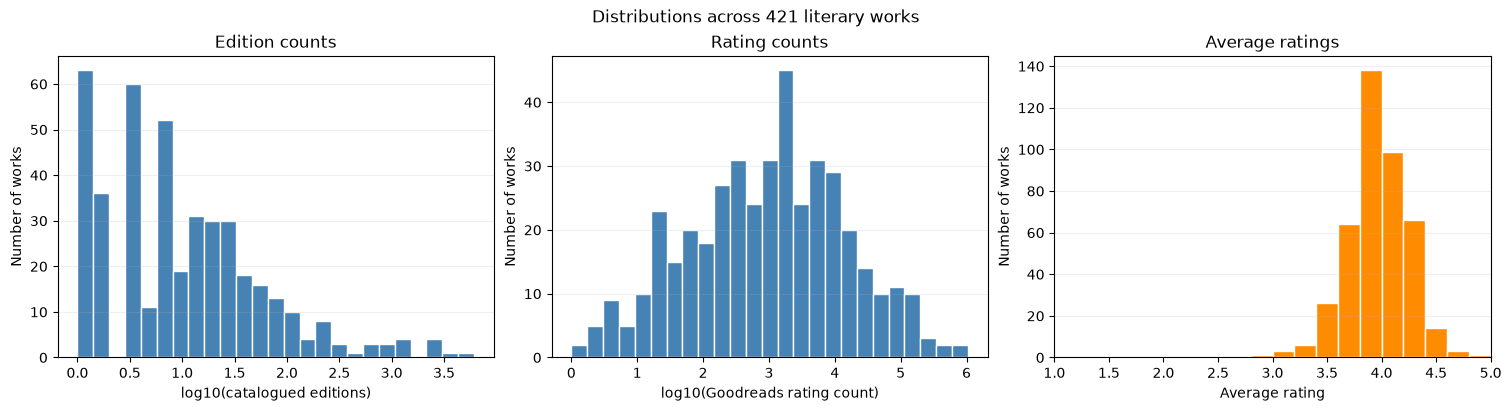

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")

axes[0].hist(
    np.log10(eda_books["edition_count"]),
    bins=25, color="steelblue", edgecolor="white",
)
axes[0].set(title="Edition counts", xlabel="log10(catalogued editions)")

axes[1].hist(
    np.log10(eda_books["ratings_count"]),
    bins=25, color="steelblue", edgecolor="white",
)
axes[1].set(title="Rating counts", xlabel="log10(Goodreads rating count)")

axes[2].hist(
    eda_books["average_rating"],
    bins=np.linspace(1, 5, 21), color="darkorange", edgecolor="white",
)
axes[2].set(title="Average ratings", xlabel="Average rating", xlim=(1, 5))

for ax in axes:
    ax.set_ylabel("Number of works")
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(f"Distributions across {len(eda_books)} literary works")
fig.savefig(FIGURES_DIR / "01_distributions.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

### Distribution Findings

Edition counts and rating counts are strongly right-skewed
on their original scales.

The median edition count is 8, compared with a mean of 97.97.
The median rating count is 1,088, compared with a mean of
18,911.99. A relatively small number of large observations
raise the means substantially.

Logarithmic displays make the variation among smaller values
easier to inspect without removing large observations.

Average ratings are concentrated around 4. The median is 3.96,
and the middle 50% of values lie between 3.82 and 4.15.

### RQ1: Edition Count and Reader Popularity

The following plots compare Open Library edition counts with
the number of ratings on the selected Goodreads records.

Both panels contain the same observations. The first uses
original scales; the second uses logarithmic scales on both axes.

This comparison makes it possible to inspect the overall range
and the pattern among observations compressed near the origin
on the original scales.

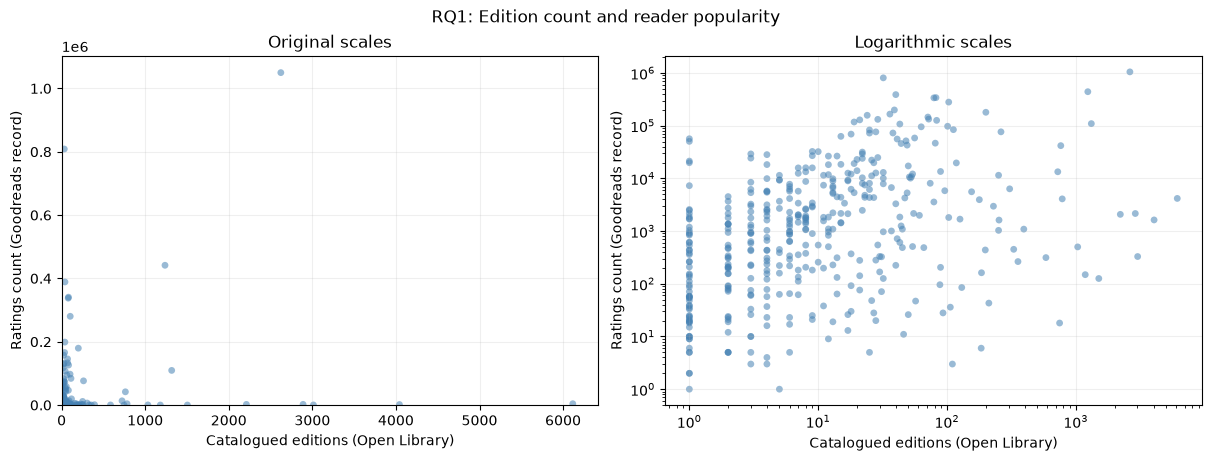

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")

for ax in axes:
    ax.scatter(
        eda_books["edition_count"],
        eda_books["ratings_count"],
        s=24, alpha=0.55, color="steelblue", edgecolors="none",
    )
    ax.set_xlabel("Catalogued editions (Open Library)")
    ax.set_ylabel("Ratings count (Goodreads record)")
    ax.grid(alpha=0.2)

axes[0].set(title="Original scales", xlim=(0, None), ylim=(0, None))
axes[1].set(title="Logarithmic scales", xscale="log", yscale="log")

fig.suptitle("RQ1: Edition count and reader popularity")
fig.savefig(FIGURES_DIR / "02_editions_vs_popularity.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

### RQ2: Reader Popularity and Average Rating

This plot compares rating counts with average ratings on the
selected Goodreads records.

Rating counts are displayed on a logarithmic axis.
Average ratings retain the full 1–5 scale.

The plot explores whether records with more ratings also tend
to have higher average ratings.

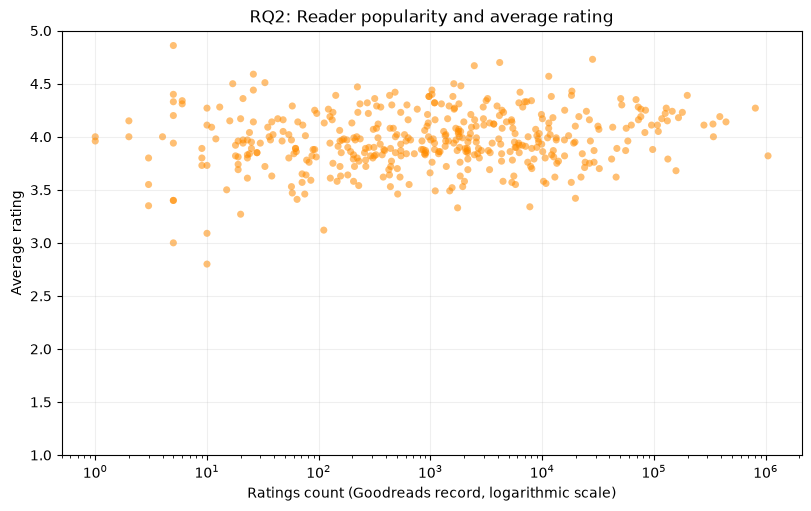

In [55]:
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")

ax.scatter(
    eda_books["ratings_count"],
    eda_books["average_rating"],
    s=26, alpha=0.55, color="darkorange", edgecolors="none",
)
ax.set(
    title="RQ2: Reader popularity and average rating",
    xlabel="Ratings count (Goodreads record, logarithmic scale)",
    ylabel="Average rating",
    xscale="log",
    ylim=(1, 5),
)
ax.grid(alpha=0.2)

fig.savefig(FIGURES_DIR / "03_popularity_vs_rating.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

### Rank Associations

Spearman's rank correlation summarizes the direction and strength
of monotonic associations between the variables.

It is suitable for exploring these relationships because the
count variables are strongly skewed and a straight-line
relationship on the original scales is not assumed.

The coefficients are calculated from the original variables.
Logarithmic transformations are used for visualization only.

These are descriptive estimates. Statistical uncertainty and
sensitivity to analytical choices will be assessed separately.

In [56]:
research_pairs = [
    ("RQ1", "edition_count", "ratings_count"),
    ("RQ2", "ratings_count", "average_rating"),
]

association_rows = []

for question, x, y in research_pairs:
    association_rows.append({
        "research_question": question,
        "x": x,
        "y": y,
        "n": len(eda_books),
        "spearman_rho": eda_books[x].corr(eda_books[y], method="spearman"),
    })

association_summary = pd.DataFrame(association_rows)
association_summary.to_csv(TABLES_DIR / "spearman_associations.csv", index=False)

display(association_summary.round({"spearman_rho": 3}))

,research_question,x,y,n,spearman_rho
0,RQ1,edition_count,ratings_count,421,0.427
1,RQ2,ratings_count,average_rating,421,0.144


### Extreme Observations

The following table combines the five largest edition counts
and the five largest rating counts. Works appearing in both
lists are displayed once.

Large values are not automatically treated as errors.
They may reflect differences in popularity, catalogue scope
or source metadata.

These observations are retained in the main dataset.
Their influence will be examined in the sensitivity analysis.

In [57]:
extreme_records = (
    pd.concat([
        eda_books.nlargest(5, "edition_count"),
        eda_books.nlargest(5, "ratings_count"),
    ])
    .drop_duplicates(subset="openlibrary_work_id")
    .sort_values("edition_count", ascending=False)
    [["title", "openlibrary_work_id", "edition_count", "ratings_count", "average_rating"]]
    .reset_index(drop=True)
)

extreme_records.to_csv(TABLES_DIR / "extreme_records.csv", index=False)
display(extreme_records)

,title,openlibrary_work_id,edition_count,ratings_count,average_rating
0,Study Bible: NIV,OL17732W,6116,4166,4.70
1,Pride and Prejudice,OL66554W,4042,1628,4.26
2,The Picture of Dorian Gray,OL8193416W,3013,329,4.08
3,Wuthering Heights,OL21177W,2889,2155,3.85
4,The Adventures of Huckleberry Finn (Adventures...,OL53908W,2623,1049912,3.82
5,Persuasion,OL66544W,1237,441462,4.14
6,The Pelican Brief,OL76965W,82,340714,4.00
7,Fight Club,OL18941W,40,388782,4.19
8,The Glass Castle,OL46760W,32,808656,4.27


### Exploratory Findings and Limitations

Across the 421 matched works, edition count and Goodreads
rating count show a positive rank association
(Spearman's rho = 0.427).

The association between rating count and average rating is
weaker (Spearman's rho = 0.144). More frequently rated records
do not consistently have substantially higher average ratings.

The count variables vary widely, while average ratings are
concentrated around 4. Logarithmic displays reveal patterns
that are difficult to inspect on the original count scales.

These findings describe associations and do not establish
causal relationships.

Edition counts refer to Open Library works, while Goodreads
measures refer to the selected representative records.
Rating counts are not totals calculated across all editions.

Edition-based sampling, matching exclusions and differences
between the two data sources limit generalization.

All validated works, including extreme observations, remain
in the main analysis. The next section will assess statistical
uncertainty and sensitivity to low rating counts, representative
record selection and extreme observations.